In [7]:
%load_ext autoreload
%autoreload 2

import iml  # helper functions and classes (see iml/)
import numpy as np  # array processing
import pandas as pd  # dataframes, reading files
import matplotlib.pyplot as plt  # making plots

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


**Group Members:**
- Grégoire Bosio
- Andres Gonçalves
- Erikas Kadisa

## Part 1: Partial Derivatives

### (a)
> Compute the derivative $\partial L / \partial x(i).$ Leaving all other
> variables fixed, what value of $x(i)$ minimizes $L$?
$$
\frac{\partial L}{\partial x(i)}
= \frac{\partial}{\partial x(i)}\left[\sum_{j=1}^{N}|\mu-x(j)| + \lambda\mu^2\right]
= \sum_{j=1}^{N}\frac{\partial|\mu-x(j)|}{\partial x(i)} + \frac{\partial \lambda\mu^2}{\partial x(i)}
= \frac{\partial|\mu-x(i)|}{\partial x(i)} + 0
$$
$$
= \frac{\partial|\mu-x(i)|}{\partial x(i)}=\frac{\partial|\mu-x(i)|}{\partial \mu-x(i)}\frac{\partial \mu-x(i)}{\partial x(i)}=\boxed{-1\times sign(\mu-x(i))},
$$
$$
\text{where } sign(x)=
\begin{cases}
1 & x > 0 \\
-1 & x < 0 
\end{cases}
$$

**Minimizer**
We define minimizer $x(i)^*$. We then observe that the function $L$ is continuous and that $\forall x(i)<x(i)^*$, $L$ is monotonically decreasing and $\forall x(i)>x(i)^*$, $L$ is monotonically increasing. $x(i)^*$ point is not differentiable due to the modular function.

We find this $x(i)^*$ by setting 
 $$
 \frac{\partial L}{\partial x(i)}=0 \Leftrightarrow  -sign(\mu-x(i))=0
 $$
 $sign(0)$ is undefined and $sign(\mu-x(i))=0$ is unreachable, meaning $sign(\mu-x(i))$ will be equal to either 1 or -1. We use one-sided limits to see how $L$ behaves around the non-differentiable point $x(i) = \mu$:
 $$ \lim_{x(i) \to \mu^-} \frac{\partial L}{\partial x(i)} = \lim_{x(i) \to \mu^-} -\operatorname{sign}(\mu - x(i)) = -1, \qquad \lim_{x(i) \to \mu^+} \frac{\partial L}{\partial x(i)} = \lim_{x(i) \to \mu^+} -\operatorname{sign}(\mu - x(i)) = +1. $$

We can see that as we approach the $\mu$ point from negative point, the $L$ is decreasing, while from positive side it is increasing. It implies that $\mu$ must be the function minimum, thus $\boxed{x(i)^* = \mu}$.

### (b)
> Compute the derivative $\partial L / \partial \mu.$ If $\lambda = 0,$ what
> values of $\mu$ minimize $L$?

$$

\frac{\partial L}{\partial \mu} 
= \frac{\sum_{i=1}^{N} \partial|\mu-x(i)|+\lambda \mu^2}{\partial \mu} 
= \sum_{i=1}^{N} \frac{ \partial|\mu-x(i)|}{\partial \mu}
+ \frac{\partial \lambda \mu^2}{\partial \mu}
= \sum_{i=1}^{N} \frac{ \partial|\mu-x(i)|}{\partial \mu}
+ 2\lambda \mu
$$
$$
= \boxed{\sum_{i=1}^{N} sign(\mu-x(i))+ 2\lambda \mu}
$$
$$
\text{where } sign(x)=
\begin{cases}
1 & x > 0 \\
-1 & x < 0 
\end{cases}, \quad x(i)\neq \mu \text{ (non-differentiable)}
$$
**Minimizer**
We define minimizer $\mu^*$.

We could find this extremum point by setting 
$$
 \frac{\partial L}{\partial \mu}=0 \Leftrightarrow  \sum_{i=1}^{N} sign(\mu-x(i))+ 2\lambda \mu=0
$$
 Since $\lambda=0$,
$$
 \sum_{i=1}^{N} sign(\mu-x(i))=0
$$
However, as mentioned before,  $sign(0)$ is undefined. Furthermore, $\mu^*$ is not trivial, as $x(i)$ varies $i \in \{1, \dots, N\}$.

We consider that $x(1)\leq x(2)\leq\dots\leq x(N)$ (if this equality is incorrect we can relabel it so that $\forall j\in\{1, \dots, N-1\} \quad x(j)\leq x(j+1)$). 

There are 2 possible cases:
1) **$N$ is odd**

In such case we would pick $\mu^*=x(m)$ for some $m \in \{1, \dots, N\}$. $L$ falls not differentiable at this point and $sign(\mu^*-x(j))=1\quad \forall j<m$, and similarly $sign(\mu^*-x(j))=-1\quad \forall j>m$. We note that we have $m-1$ and $(N-m)$ such terms respectively. To minimize $L$ we want:
		
		
$$
\sum_{i=1,\; i\neq m}^{N} sign(\mu-x(i))=0 \implies (m-1)-(N-m)=2m-N-1=0
$$

$$
2m-N-1=0 \implies m=\frac{N+1}{2} \text{ (median formula for odd N)}
$$
		 
So, $\mu^*=x(m)=x\left(\frac{N+1}{2}\right)$ if $N$ is odd.
2) **$N$ is even**

In such case we would pick $\mu^*\in (x(m), x(m+1))$ for some $m \in \{1, \dots, N-1\}$. $L$ is differentiable at $\mu^*$ point (since it lies between any two points) and $sign(\mu^*-x(j))=1\quad \forall j\leq m$, and similarly $sign(\mu^*-x(j))=-1\quad \forall j \geq m+1$. We note that we have $m$ and $(N-m)$ such terms respectively. To minimize $L$ we want:
$$
	\sum_{i=1}^{N} sign(\mu-x(i))=0 \implies (m)-(N-m)=2m-N=0
$$

$$
	2m-N=0 \implies m=\frac{N}{2}
$$

So, $\mu^*\in (x(m), x(m+1))\implies \mu^*\in \left( x\left( \frac{N}{2} \right), x\left( \frac{N}{2}+1 \right) \right)$. Important detail to note is that in this interval derivative is 0 and function is continuous, meaning that the function is constant. It implies that the interval corners can also be the minimizers, even if they are not differentiable.

So the minimizer is:
$$
\mu^*\in
\begin{cases} \left\{x\left (\frac{ N+1}{2} \right) \right\} & \text{if }N \text{ is odd}\\  \left[x\left (\frac{ N}{2} \right), x\left (\frac{ N}{2}+1 \right) \right] & \text{if }N \text{ is even}\\  \end{cases}
$$

### (c)
> Compute the derivative $\partial L / \partial \theta.$

Define $f=|\mu-x(i)|$, $g=\lambda \mu^2$
  

$$

\frac{\partial L}{\partial \theta} = \frac{\partial \sum_{i=1}^{N} f+g}{\partial \theta}
=\sum_{i=1}^{N} \frac{\partial f}{\partial \theta}+\frac{\partial g}{\partial \theta}

$$

$$
1) \; \frac{\partial f}{\partial \theta} = \frac{\partial |\mu-x(i)|}{\partial \theta} = \frac{\partial |\mu-x(i)|}{\partial \mu} \frac{\partial \mu}{\partial \theta}
=sign(\mu-x(i))\times 3\theta^2=3\theta^2sign(\mu-x(i))
$$

$$
2)\; \frac{\partial g}{\partial \theta} = \frac{\partial \lambda \mu ^2}{\partial \theta }=
 \frac{\partial \lambda \mu ^2}{\partial \mu}\frac{\partial \mu}{\partial \theta }
 =2\lambda \mu \times 3\theta ^2=6\lambda \theta^5
$$

  **Result**:
$$
  \frac{\partial L}{\partial \theta}
  = \sum_{i=1}^{N} 3\theta^2sign(\mu-x(i))+6\lambda \theta^5
  =\boxed{3\theta^2 \left[ \sum_{i=1}^{N} \operatorname{sign}(\theta^3-x(i)) + 2\lambda \theta^3 \right]}
$$

### (d)
> Compute $$
> \frac{\partial}{\partial z_i} \ln \operatorname{softmax}(z)_j.$$
> (Hint: first define $Z = \ln \sum_{j = 1}^k e^{z_j}$ and compute
> $\partial Z / \partial z_j.$)


$$\ln \mathrm{softmax}(z)_j = \ln\left( \frac{e^{z_{j}}}{\sum_{m=1}^{k}e^{z_{m}}} \right)=\ln(e^{z_{j}})-\ln(\sum_{m=1}^{k}e^{z_{m}})=z_{j}-Z$$
$$\frac{\partial\ln \mathrm{softmax}(z)_j}{\partial z_{i}}=\frac{\partial z_{j}}{\partial z_{i}}-\frac{\partial Z}{\partial z_{i}}$$
We calculate parts:
$$1) \; \dfrac{\partial z_j}{\partial z_i} = \delta_{ij}=\begin{cases} 
1 & \text{if } i=j \\[2ex] 
0 & \text{otherwise} 
\end{cases}$$

Define $u=e^Z$ (i.e. $\ln u = Z$)
$$2) \; \dfrac{\partial Z}{\partial z_i} =\frac{\partial \ln\left( \sum_{m=1}^{k}e^{z_{m}} \right)}{\partial z_{i}}= \frac{\partial \ln u}{\partial u}\frac{\partial u}{\partial z_{i}}=\frac{1}{u}\frac{\partial \sum_{m=1}^{k} e^{z_{m}}}{\partial z_{i}}=
\frac{e^{z_{i}}}{ \sum_{m=1}^{k} e^{z_{m}}}=softmax(z)_{i}$$

**Result**:
$$\frac{\partial\ln \mathrm{softmax}(z)_j}{\partial z_{i}}
=\boxed{\delta_{ij}-softmax(z)_{i}},$$
$$\text{where } \delta_{ij}=\begin{cases} 
1 & \text{if } i=j \\[2ex] 
0 & \text{otherwise} 
\end{cases}$$

## Part 2: Linear Regression

### (a)
> Consider the linear model, defined by parameters $(\theta_0, \theta_1)$,
> which predicts $$
> \hat y(i) = \theta_0 + \theta_1 x(i)$$ 
> for each index
> $i.$ Express the gradient $\nabla L$ of mean squared error as a function of
> the parameter vector $\theta$ and the datapoints $(x(i), y(i)).$

Since here we consider only $P=2$ (i.e. $\widehat {y}=\theta_{0}+\theta_{1}x(i)$), we get that $\nabla L=\left[ \frac{\partial L}{\partial \theta_{0}}, \frac{\partial L}{\partial \theta_{1}} \right]$.
$$
L=\frac{1}{N}\sum_{i=1}^{N} (\hat{y}(i)-y(i))^2=\frac{1}{N}\sum_{i=1}^{N}(\theta_{0}+\theta_{1}x(i)-y(i))^2
$$

$$
\frac{\partial L}{\partial \theta_{j}}=\frac{\partial}{\partial \theta_{j}}\frac{1}{N}\sum_{i=1}^{N}(\theta_{0}+\theta_{1}x(i)-y(i))^2
=\frac{1}{N}\sum_{i=1}^{N}\frac{\partial}{\partial \theta_{j}}(\theta_{0}+\theta_{1}x(i)-y(i))^2
$$
Let $f=\theta_{0}+\theta_{1}x(i)-y(i)$

$$
\implies \frac{1}{N}\sum_{i=1}^{N}\frac{\partial (f)^2}{\partial f} \frac{\partial f}{\partial \theta_{j}}
=\frac{1}{N}\sum_{i=1}^{N}\left(2f\times\frac{\partial (\theta_{0}+\theta_{1}x(i))}{\partial \theta_{j}}\right)
=\frac{2}{N}\sum_{i=1}^{N}\left(f\times\frac{\partial (\theta_{0}+\theta_{1}x(i))}{\partial \theta_{j}}\right)
$$
Then we calculate partial derivatives:
$$
\frac{\partial L}{\partial \theta_{0}}=\frac{2}{N}\sum_{i=1}^{N}\left(f\times\frac{\partial (\theta_{0}+\theta_{1}x(i))}{\partial \theta_{0}}\right)
=\frac{2}{N}\sum_{i=1}^{N}\left(f\times 1\right)
=\frac{2}{N}\sum_{i=1}^{N}\left(\theta_{0}+\theta_{1}x(i)-y(i)\right)
$$

$$
\frac{\partial L}{\partial \theta_{1}}=\frac{2}{N}\sum_{i=1}^{N}\left(f\times\frac{\partial (\theta_{0}+\theta_{1}x(i))}{\partial \theta_{1}}\right)
=\frac{2}{N}\sum_{i=1}^{N}\left(f\times x(i)\right)
=\frac{2}{N}\sum_{i=1}^{N}\left(x(i)(\theta_{0}+\theta_{1}x(i)-y(i))\right)
$$
$$
\nabla L=\left[ \frac{2}{N}\sum_{i=1}^{N}\left(\theta_{0}+\theta_{1}x(i)-y(i)\right), \frac{2}{N}\sum_{i=1}^{N}\left(x(i)(\theta_{0}+\theta_{1}x(i)-y(i))\right) \right]
$$

### (b)
> Extend the `SimpleRegressor` class from `iml/simple_regressor.py`,
> implementing the method `fit(self, x, y, lr, steps)` to implement gradient
> descent on mean squared error. Run `fit()` on the _unnormalized_ data
> vectors `x` and `y`, and show the training process over 20 iterations with
> `SimpleRegressor.show_training()`. Find a learning rate that makes the loss
> decrease.

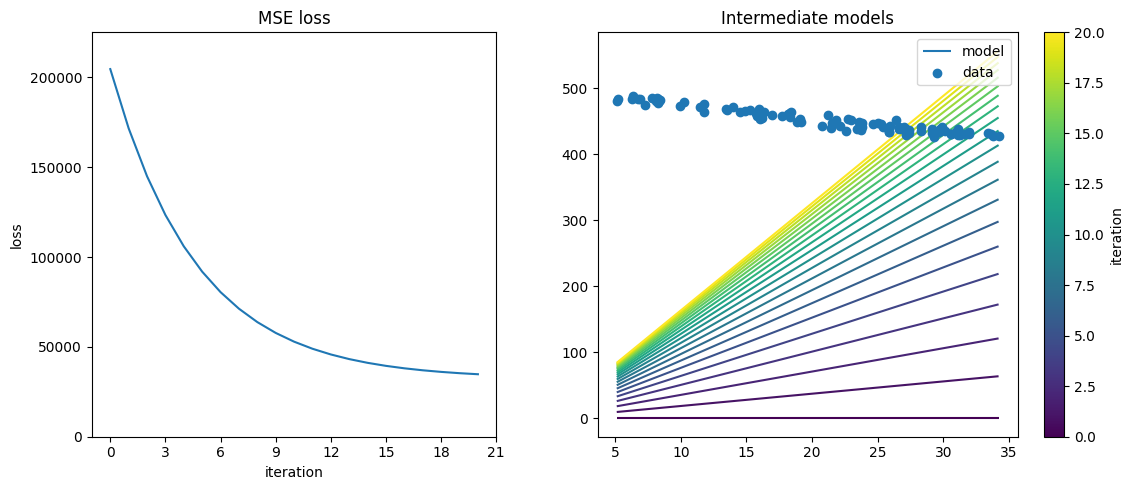

In [8]:
x, y = iml.load_powerplant()

class Regressor(iml.SimpleRegressor):
    def __init__(self):
        pass

    def fit(self, x, y, lr: float, steps: int = 20) -> None:
            # x and y are vectors of the same length
    
            self.weights_ = np.zeros(2)  # a vector with the two parameters of our model
    
            # we keep copies of the x, y and the predicted outputs at each
            # iteration to use them in show_training() later
            self.x_train_ = x.copy()
            self.y_train_ = y.copy()
            self.y_predicted_ = np.zeros((steps + 1, y.shape[0]))
            self.y_predicted_[0] = self.predict(x)

            n = len(x)

            for i in range(steps):
                # here: update self.weights_?
                prediction = self.predict(x)
                error = prediction - y

                grad0 = 2/n*np.sum(error)
                grad1 = 2/n*np.sum(error*x)

                self.weights_[0] -= lr*grad0
                self.weights_[1] -= lr*grad1

                self.y_predicted_[i + 1] = self.predict(x)
    
            return None

model = Regressor()
lr = 1e-4
model.fit(x, y, lr, 20)
model.show_training()
    


### (c)
> Now, normalize your data in some way and run `fit()` and `show_training()`
> again, ensuring that you converge to an acceptable model in 20 iterations.

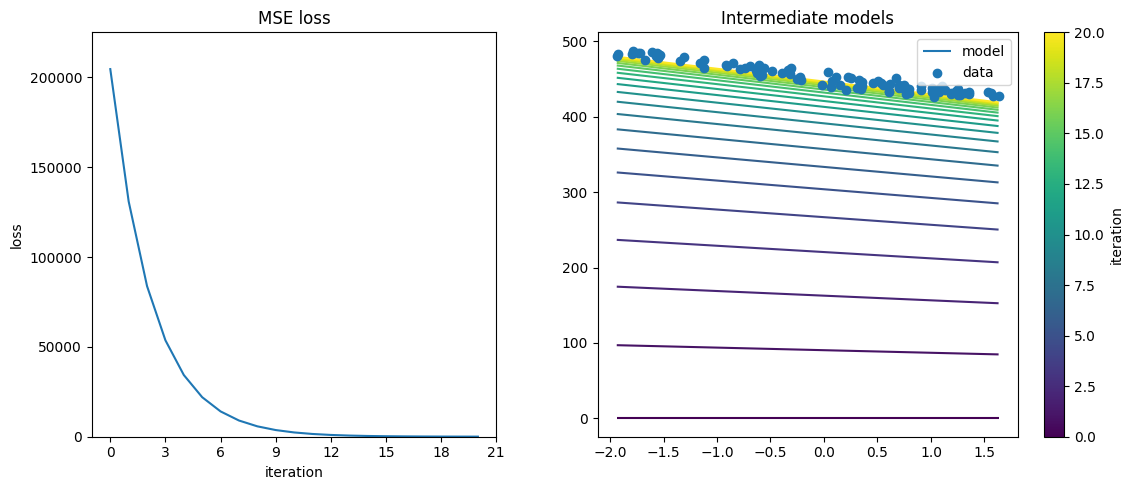

In [9]:
def normalize_min_max(x):
    return (x - x.min()) / (x.max() - x.min())

def normalize_z_score(x):
    return (x - x.mean()) / x.std()

x_norm = normalize_z_score(x)

model = Regressor()
model.fit(x_norm, y, lr=0.1, steps=20)
model.show_training()

## Part 3: k-Means and PCA

### (a)
> Suppose we didn't have access to the species attribute of the iris dataset.
> Implement the Lloyd-Forgy algorithm for $k$-means and use it to infer a
> partition of the iris dataset into three species. Compute the confusion
> matrix and the accuracy of the partition relative to the true species.

Converged after 6 iterations, final WCSS = 78.85

Confusion matrix (rows = true, columns = predicted):
            setosa  versicolor  virginica
setosa          50           0          0
versicolor       0          48          2
virginica        0          14         36

Accuracy: 0.893


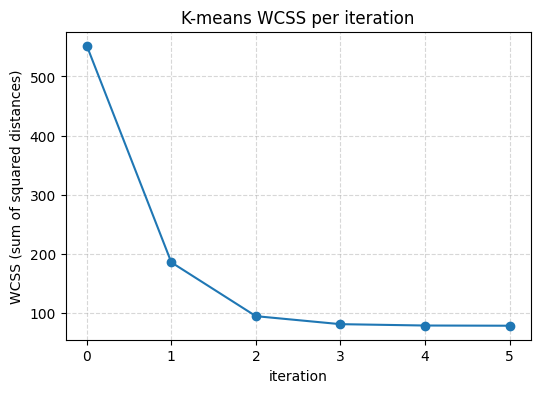

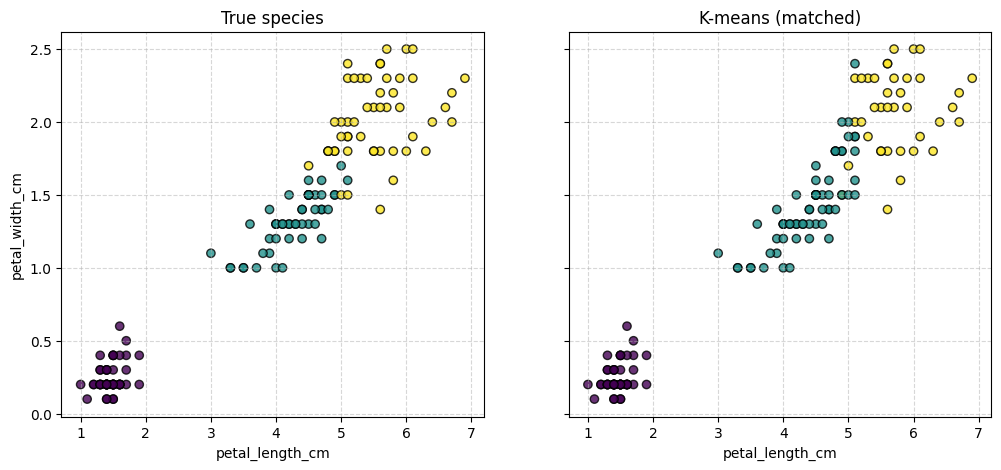

In [10]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# ---------------------------------------------------------------------------
# Data (species labels are kept aside and only used for evaluation)
# ---------------------------------------------------------------------------
iris = iml.load_iris()
feature_names = ["sepal_length_cm", "sepal_width_cm", "petal_length_cm", "petal_width_cm"]
df = pd.DataFrame(iris.data, columns=feature_names)

X = df.values                      # (N, 4)
y_true = np.asarray(iris.target)   # (N,)  0/1/2 — NOT used by k-means
species = list(iris.target_names)


# ---------------------------------------------------------------------------
# Lloyd-Forgy k-means
# ---------------------------------------------------------------------------
def kmeans(X, k, max_steps=100, seed=9):
    rng = np.random.default_rng(seed)

    # 1. Forgy init: k random observations as initial centroids
    centroids = X[rng.choice(len(X), k, replace=False)].astype(float)
    history = {"centroids": [centroids.copy()], "labels": [], "loss": []}
    prev_labels = None

    for _ in range(max_steps):
        # 2. Assign each point to its nearest centroid
        dist = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)  # (N, k)
        labels = np.argmin(dist, axis=1)                                     # (N,)

        # WCSS: sum of SQUARED distances to the assigned centroid
        wcss = np.sum(dist[np.arange(len(X)), labels] ** 2)
        history["labels"].append(labels.copy())
        history["loss"].append(wcss)

        # 4. Stop when assignments no longer change
        if prev_labels is not None and np.array_equal(labels, prev_labels):
            break
        prev_labels = labels

        # 3. Recompute centroids as the mean of their assigned points
        for i in range(k):
            pts = X[labels == i]
            if len(pts) > 0:  # keep old centroid if a cluster goes empty
                centroids[i] = pts.mean(axis=0)
        history["centroids"].append(centroids.copy())

    return history


def best_kmeans(X, k, n_init=10):
    """K-means only finds a local optimum: run several inits, keep lowest final WCSS."""
    runs = [kmeans(X, k, seed=s) for s in range(n_init)]
    return min(runs, key=lambda h: h["loss"][-1])


# ---------------------------------------------------------------------------
# Evaluation
# ---------------------------------------------------------------------------
def match_clusters(y_true, labels, k):
    """Cluster IDs are arbitrary. Find the cluster->species mapping with the most matches."""
    best_mapped, best_correct = None, -1
    for perm in itertools.permutations(range(k)):
        mapped = np.array(perm)[labels]  # perm[c] = species assigned to cluster c
        correct = np.sum(mapped == y_true)
        if correct > best_correct:
            best_mapped, best_correct = mapped, correct
    return best_mapped


def confusion_matrix(y_true, y_pred, n_classes):
    cm = np.zeros((n_classes, n_classes), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1   # rows = true species, columns = predicted
    return cm


# ---------------------------------------------------------------------------
# Plots
# ---------------------------------------------------------------------------
def plot_loss(history):
    plt.figure(figsize=(6, 4))
    plt.plot(history["loss"], marker="o")
    plt.title("K-means WCSS per iteration")
    plt.xlabel("iteration")
    plt.ylabel("WCSS (sum of squared distances)")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.show()


def plot_true_vs_pred(X, y_true, y_pred, x_idx=2, y_idx=3):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
    for ax, labels, title in [(axes[0], y_true, "True species"),
                              (axes[1], y_pred, "K-means (matched)")]:
        ax.scatter(X[:, x_idx], X[:, y_idx], c=labels, cmap="viridis",
                   vmin=0, vmax=2, edgecolors="k", alpha=0.8)
        ax.set_title(title)
        ax.set_xlabel(feature_names[x_idx])
        ax.grid(True, linestyle="--", alpha=0.5)
    axes[0].set_ylabel(feature_names[y_idx])
    plt.show()


def play_kmeans_notebook(X, history, k, x_idx=2, y_idx=3):
    fig, ax = plt.subplots(figsize=(8, 5))
    num_steps = len(history["labels"])

    scatter = ax.scatter(X[:, x_idx], X[:, y_idx], c=history["labels"][0],
                         cmap="viridis", edgecolors="k", alpha=0.8, zorder=2)
    scatter.set_clim(0, k - 1)  # fixed colors across frames
    cents = ax.scatter([], [], c="red", marker="X", s=250, edgecolors="black", zorder=5)

    ax.set_xlabel(feature_names[x_idx])
    ax.set_ylabel(feature_names[y_idx])
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.set_xlim(X[:, x_idx].min() - 0.5, X[:, x_idx].max() + 0.5)
    ax.set_ylim(X[:, y_idx].min() - 0.5, X[:, y_idx].max() + 0.5)

    def update(step):
        scatter.set_array(history["labels"][step])
        cents.set_offsets(history["centroids"][step][:, [x_idx, y_idx]])
        ax.set_title(f"K-means iteration {step} | WCSS: {history['loss'][step]:.2f}")
        return scatter, cents

    anim = FuncAnimation(fig, update, frames=num_steps, interval=800, blit=False)
    plt.close(fig)
    display(HTML(anim.to_jshtml()))


# ---------------------------------------------------------------------------
# Run
# ---------------------------------------------------------------------------
k = 3
history = best_kmeans(X, k)
labels = history["labels"][-1]

y_pred = match_clusters(y_true, labels, k)
cm = confusion_matrix(y_true, y_pred, k)
accuracy = np.trace(cm) / cm.sum()

print(f"Converged after {len(history['labels'])} iterations, final WCSS = {history['loss'][-1]:.2f}")
print("\nConfusion matrix (rows = true, columns = predicted):")
print(pd.DataFrame(cm, index=species, columns=species))
print(f"\nAccuracy: {accuracy:.3f}")

plot_loss(history)
plot_true_vs_pred(X, y_true, y_pred)
play_kmeans_notebook(X, history, k)

### (b)
> Investigate `data/ulu.csv` using PCA and explain how this dataset was
> produced. Using scikit-learn, run both $k$-means clustering and DBSCAN on
> this dataset. Which method produces more reasonable "clusters"?

dimension importance: [0.8730992  0.11963923 0.00726156]
cummulative importance: [0.8730992  0.99273844 1.        ]


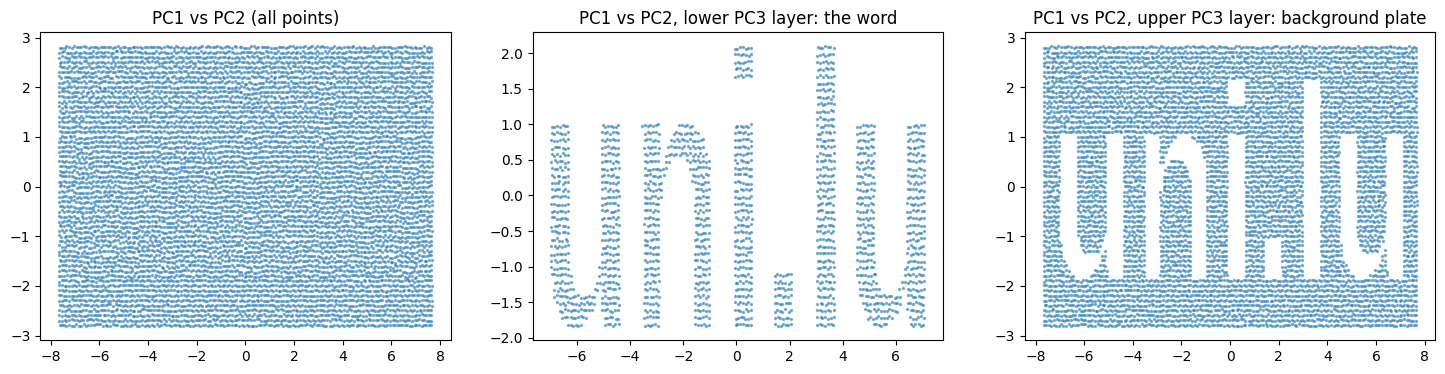

DBSCAN clusters (label, size): (array([0, 1, 2, 3, 4, 5, 6, 7]), array([ 437, 6935,  203,  280,  437,  395,   56,   35]))


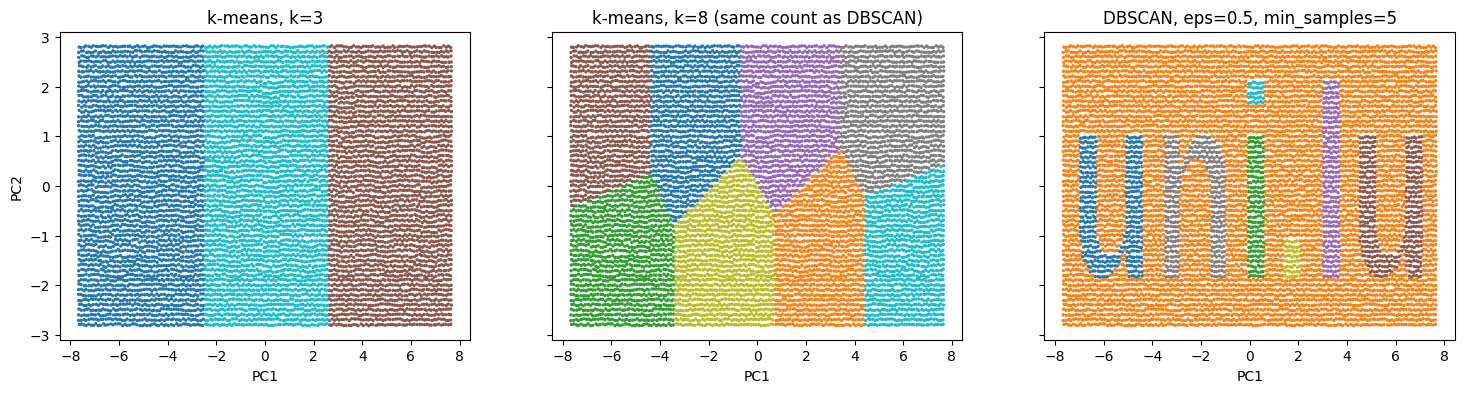

In [11]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN

data = iml.load_ulu()

pca = PCA(n_components=3)
Z = pca.fit_transform(data)
print(f"dimension importance: {pca.explained_variance_ratio_}")
print(f"cummulative importance: {np.cumsum(pca.explained_variance_ratio_)}")

# PCA views: PC3 only separates the two layers (word vs background plate)
layer = Z[:, 2] > -0.4
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].scatter(Z[:, 0], Z[:, 1], s=2, alpha=0.5)
axes[0].set_title("PC1 vs PC2 (all points)")
axes[1].scatter(Z[~layer, 0], Z[~layer, 1], s=2, alpha=0.5)
axes[1].set_title("PC1 vs PC2, lower PC3 layer: the word")
axes[2].scatter(Z[layer, 0], Z[layer, 1], s=2, alpha=0.5)
axes[2].set_title("PC1 vs PC2, upper PC3 layer: background plate")
plt.show()

# clustering on the raw data, visualised in PCA space
km3 = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(data)
km8 = KMeans(n_clusters=8, n_init=10, random_state=0).fit_predict(data)
db = DBSCAN(eps=0.5, min_samples=5).fit_predict(data)
print("DBSCAN clusters (label, size):", np.unique(db, return_counts=True))

results = [("k-means, k=3", km3), ("k-means, k=8 (same count as DBSCAN)", km8), ("DBSCAN, eps=0.5, min_samples=5", db)]
fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharex=True, sharey=True)
for ax, (title, lab) in zip(axes, results):
    ax.scatter(Z[:, 0], Z[:, 1], c=lab, cmap="tab10", s=2)
    ax.set_title(title)
    ax.set_xlabel("PC1")
axes[0].set_ylabel("PC2")
plt.show()


**PCA.** The explained variance ratios are 0.873, 0.120 and 0.007. The first two components together explain 99.3% of the variance, so the 3D data lies almost entirely on a 2D plane that is rotated inside 3D space. PCA undoes the rotation.

- the lower layer contains only the letters spelling **"uni.lu"**;
- the upper layer is a filled background rectangle with the text cut out.

**How the data was produced.** The word "uni.lu" was sampled as 2D points, and a background rectangle with the same word removed was sampled as a second set of 2D points. The two sets were placed on parallel planes with a small offset between them, which is the PC3 gap. The result was then rotated and shifted into 3D, and noise was added.

**k-means vs DBSCAN.** k-means with k=3 cuts the rectangle into three vertical slabs. With k=8 (the same number of clusters as DBSCAN) it cuts the plate into Voronoi cells that ignore the letters. k-means assumes compact, roughly round clusters of similar size, and this data is not like that, so it ignores the real structure.

DBSCAN (eps=0.5, min_samples=5) finds 8 clusters: the background plate and each piece of the word as its own cluster (u, n, i, the dot of the i, ".", l, u). It follows density and connectivity, so it matches the real structure. **DBSCAN is more reasonable.**
